# Visualize Hidden-State Projections and SVD Energy

This Visualize notebook loads the cached data produced by `Generate-hidden-state-projections-and-SVD-energy.ipynb` and presents two hidden-state figures for the main numerical input families at $N = 500$ using Llama-3.2-3B, as presented under **Attention-Induced Token Graphs: Construction and Visualization Robustness** in the appendix.

The first figure projects last-layer token hidden states onto the leading three uncentered SVD coordinates; these coordinates define the RGB node colors used in the attention-induced graph visualizations.

The second figure shows cumulative hidden-state SVD-energy fraction, averaged first across input families within each layer and then across the analyzed layers. The leading three components capture approximately 75% of the energy on average.


Define input sets and plotting defaults.


In [ ]:
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# 500-token analysis window
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS
PROCESSED_DATA_DIR = Path('processed_hidden_state_data')
FIGURE_OUTPUT_DIR = Path('figure')

# All cached inputs, ordered from simple and periodic to chaotic dynamics
ALL_DATA_ORDER = [
    'Constant 500',
    'Logistic r=3.2',
    'Logistic r=3.5',
    'Logistic r=3.55',
    'Logistic r=3.566',
    'Logistic r=3.5692',
    'Logistic r=3.5698',
    'Logistic r=3.9',
    'Logistic r=4.0',
    'Lorenz',
]

ENERGY_SUMMARY_DATA_ORDER = ALL_DATA_ORDER

SVD_COMPONENTS = (1, 2, 3)
ORIENT_COMPONENT_SIGNS_BY_TOKEN_ORDER = False
ENERGY_PLOT_MAX_MODES = 25

DISPLAY_DPI = 150
PDF_DPI = 300

# All-inputs projection figure layout
ALL_INPUTS_FIGURE_SIZE = (18.4, 7.6)
ALL_INPUTS_GRID_N_ROWS = 2
ALL_INPUTS_GRID_N_COLS = 5
ALL_INPUTS_SUBPLOT_ADJUST = dict(left=0.085, right=0.935, bottom=0.120, top=0.900, wspace=0.00, hspace=0.245)
ALL_INPUTS_SAVEFIG_PAD_INCHES = 0.035
ALL_INPUTS_FIGURE_FONT_SIZE_SCALE = 1.0
ALL_INPUTS_PANEL_TITLE_FONT_SIZE = 13.5 * ALL_INPUTS_FIGURE_FONT_SIZE_SCALE
ALL_INPUTS_PANEL_TITLE_Y_OFFSET = 0.006
ALL_INPUTS_AXIS_LABEL_FONT_SIZE = 11.55 * ALL_INPUTS_FIGURE_FONT_SIZE_SCALE
ALL_INPUTS_SVD_TICK_LABEL_FONT_SIZE = 8.5 * ALL_INPUTS_FIGURE_FONT_SIZE_SCALE
ALL_INPUTS_LEGEND_FONT_SIZE = 1.1 * ALL_INPUTS_AXIS_LABEL_FONT_SIZE
ALL_INPUTS_TRAJECTORY_LEGEND_ANCHOR = (0.271, 0.038)
ALL_INPUTS_RGB_SIGNAL_LEGEND_ANCHOR = (0.685, 0.038)
ALL_INPUTS_SVD_Z_LABEL_X = -0.035
ALL_INPUTS_SVD_Z_LABEL_Y = 0.52

# 3D projection drawing style
ALL_INPUTS_STATE_NODE_SIZE = 8
ALL_INPUTS_DELIMITER_NODE_SIZE = 15 * 1.35
DELIMITER_NODE_EDGE_COLOR = '#666666'
DELIMITER_NODE_EDGE_WIDTH = 0.5
RGB_SIGNAL_NODE_ALPHA = 0.95
AXIS_MARGIN_FRAC = 0.055
SVD_AXIS_CLIP_QUANTILES = (0.0, 1.0)
VIEW_ELEV = 15
VIEW_AZIM = 45
THREE_D_GRID_COLOR = '#D6D6D6'
THREE_D_GRID_LINE_WIDTH = 0.45
SVD_AXIS_GRID_NBINS = 5
SVD_AXIS_GRID_MIN_TICKS = 4
AXIS_PANE_COLOR = (0.985, 0.985, 0.985, 0.45)
AXIS_PANE_EDGE_COLOR = (0.985, 0.985, 0.985, 0.45)
AXIS_LINE_COLOR = 'black'
TICK_COLOR = '#333333'

# Cumulative-energy figure style
ENERGY_FIGURE_SIZE = (0.96 * 4.35, 0.8 * 4.35)
ENERGY_SAVEFIG_PAD_INCHES = 0.08
ENERGY_FIGURE_FONT_SIZE_SCALE = 1.155
ENERGY_AXIS_LABEL_FONT_SIZE = 9.8 * ENERGY_FIGURE_FONT_SIZE_SCALE
ENERGY_TICK_LABEL_FONT_SIZE = 7.0 * ENERGY_FIGURE_FONT_SIZE_SCALE
ENERGY_PANEL_BOX_ASPECT = 1.0
ENERGY_MEAN_COLOR = '#4A4A4A'
ENERGY_STD_BAND_COLOR = '#111111'
ENERGY_STD_BAND_ALPHA = 0.12
ENERGY_MARK_COLOR = '#B87912'
ENERGY_MARKER_SYMBOL = 'D'
ENERGY_GUIDE_COLOR = '#D9A441'
ENERGY_GRID_COLOR = '#E4E8EF'
ENERGY_SPINE_COLOR = '#AAB3BF'
ENERGY_PANEL_FACE_COLOR = '#FCFDFE'
ENERGY_MARK_MODE = 3
ENERGY_MARK_LABEL_FONT_SIZE = 8.8 * ENERGY_FIGURE_FONT_SIZE_SCALE
CUMULATIVE_ENERGY_X_LEFT_PAD = 0.5
CUMULATIVE_ENERGY_X_RIGHT_PAD = 0.5
CUMULATIVE_ENERGY_Y_LIMIT = (0.4, 1.0)
CUMULATIVE_ENERGY_Y_TICK_STEP = 0.20

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['savefig.dpi'] = PDF_DPI


In [2]:
# Input-family display labels and relative cache schema
DATA_TITLE_OVERRIDES = {
    'Constant 500': 'Constant sequence',
}

DATA_TITLE_SUFFIXES = {
    'Logistic r=3.2': 'period 2',
    'Logistic r=3.5': 'period 4',
    'Logistic r=3.55': 'period 8',
    'Logistic r=3.566': 'period 16',
    'Logistic r=3.5692': 'period 32',
    'Logistic r=3.5698': 'period 64',
    'Logistic r=3.9': 'chaotic',
    'Logistic r=4.0': 'chaotic',
    'Lorenz': 'chaotic',
}

HIDDEN_STATE_ARRAY_KEYS = (
    'layer_indices',
    'svd_cumulative_energy_ratio',
    'final_layer_index',
    'svd_projection_coords',
    'is_delimiter',
)


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f'{title} ({suffix})' if suffix else title


def context_fraction_label(frac):
    # Preserve the context50 cache-label convention used by the Generate notebook
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def hidden_state_data_path(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_hidden_state_data.npz'


Load and validate the cached hidden-state SVD arrays.

Energy convention: `svd_cumulative_energy_ratio[k]` is cumulative through mode `k + 1`; therefore, `svd_cumulative_energy_ratio[2]` is the energy fraction captured by the leading three components.


In [3]:
def load_processed_hidden_state_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    path = hidden_state_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        missing = [key for key in HIDDEN_STATE_ARRAY_KEYS if key not in npz.files]
        if missing:
            raise KeyError(f'{path} is missing required arrays: {missing}')
        processed_data = {key: npz[key] for key in HIDDEN_STATE_ARRAY_KEYS}

    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    final_layer_index = int(np.asarray(processed_data['final_layer_index']).item())
    coords = np.asarray(processed_data['svd_projection_coords'])
    cumulative_energy = np.asarray(processed_data['svd_cumulative_energy_ratio'])
    is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)

    if layer_indices.ndim != 1 or layer_indices.size == 0:
        raise ValueError(f'{path}: layer_indices must be a nonempty 1D array')
    if final_layer_index not in layer_indices:
        raise ValueError(f'{path}: final_layer_index is absent from layer_indices')
    if coords.ndim != 2:
        raise ValueError(f'{path}: svd_projection_coords must have shape (tokens, components), got {coords.shape}')
    if coords.shape[0] != is_delimiter.size:
        raise ValueError(f'{path}: svd_projection_coords and is_delimiter disagree on token count')
    if cumulative_energy.ndim != 2 or cumulative_energy.shape[0] != layer_indices.size:
        raise ValueError(f'{path}: svd_cumulative_energy_ratio must have one row per saved layer')

    return processed_data


def load_processed_svd_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    # Present the final-layer portion of the unified archive to projection helpers
    processed_data = load_processed_hidden_state_data(data_name, frac=frac, data_dir=data_dir)
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    final_layer_index = int(np.asarray(processed_data['final_layer_index']).item())
    final_offset = int(np.flatnonzero(layer_indices == final_layer_index)[0])
    cumulative_energy = np.asarray(processed_data['svd_cumulative_energy_ratio'])
    return {
        'layer_indices': np.asarray([final_layer_index], dtype=int),
        'svd_projection_coords': np.asarray(processed_data['svd_projection_coords'])[None, :, :],
        'svd_cumulative_energy_ratio': cumulative_energy[final_offset:final_offset + 1],
        'is_delimiter': np.asarray(processed_data['is_delimiter'], dtype=bool),
    }


def check_processed_svd_data(data_names=ALL_DATA_ORDER, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = hidden_state_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_processed_svd_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing processed hidden-state data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed hidden-state data:\n' + details)


def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = ', '.join(str(int(layer)) for layer in layer_indices) if layer_indices.size else 'none'
        raise ValueError(f'Layer {layer_index} is unavailable. Available one-based layers: {available}')
    return int(matches[0])


def available_layer_indices(data_name=ALL_DATA_ORDER[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_svd_data(data_name, frac=frac, data_dir=data_dir)
    return np.asarray(processed_data['layer_indices'], dtype=int)


def load_layerwise_svd_energy_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_hidden_state_data(data_name, frac=frac, data_dir=data_dir)
    return {
        'layer_indices': np.asarray(processed_data['layer_indices'], dtype=int),
        'svd_cumulative_energy_ratio': np.asarray(processed_data['svd_cumulative_energy_ratio']),
        'is_delimiter': np.asarray(processed_data['is_delimiter'], dtype=bool),
    }


Collect RGB-colored 3D coordinates and average cumulative-energy curves first across inputs within each layer, then across layers.


In [4]:
def component_indices_from_one_based(svd_components):
    components = tuple(int(component) for component in svd_components)
    if len(components) != 3:
        raise ValueError('Choose exactly three SVD components for the 3D plot, for example (1, 2, 3).')
    if any(component < 1 for component in components):
        raise ValueError('Use one-based SVD component numbers.')
    return tuple(component - 1 for component in components)


# Optional deterministic orientation resolves the arbitrary sign of each SVD component
def orient_component_signs_by_token_order(coords, eps=1e-12):
    coords = np.asarray(coords, dtype=float).copy()
    if coords.ndim != 2 or coords.shape[0] < 2:
        return coords

    t = np.arange(coords.shape[0], dtype=float)
    t_centered = t - np.mean(t)
    for component_idx in range(coords.shape[1]):
        col = coords[:, component_idx]
        finite = np.isfinite(col)
        if np.count_nonzero(finite) < 2:
            continue
        col_centered = col[finite] - np.mean(col[finite])
        score = float(np.dot(t_centered[finite], col_centered))
        if score < -eps:
            coords[:, component_idx] *= -1.0
        elif abs(score) <= eps:
            valid_positions = np.flatnonzero(finite)
            if valid_positions.size >= 2 and col[valid_positions[-1]] < col[valid_positions[0]]:
                coords[:, component_idx] *= -1.0
    return coords


# Map the three selected coordinate columns independently to red, green, and blue
def _minmax_scale_rgb_channels(coords, fill_value=0.5, eps=1e-12):
    coords = np.asarray(coords, dtype=float)
    if coords.ndim == 1:
        coords = coords[:, None]
    if coords.ndim != 2:
        raise ValueError('coords must be 2D (num_tokens x num_components)')

    n = coords.shape[0]
    rgb = np.full((n, 3), float(fill_value), dtype=float)
    if n == 0:
        return rgb

    for k in range(3):
        if coords.shape[1] <= k:
            continue
        col = np.asarray(coords[:, k], dtype=float)
        finite = np.isfinite(col)
        if not np.any(finite):
            continue
        cmin = float(np.min(col[finite]))
        cmax = float(np.max(col[finite]))
        if (cmax - cmin) <= float(eps):
            rgb[finite, k] = float(fill_value)
        else:
            rgb[finite, k] = (col[finite] - cmin) / (cmax - cmin)

    rgb[~np.isfinite(rgb)] = float(fill_value)
    return np.clip(rgb, 0.0, 1.0)


def collect_rgb_svd_panel_data(
    layer_index,
    svd_components=SVD_COMPONENTS,
    frac=CONTEXT_FRAC,
    data_names=ALL_DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    orient_signs=ORIENT_COMPONENT_SIGNS_BY_TOKEN_ORDER,
):
    layer_index = int(layer_index)
    component_indices = component_indices_from_one_based(svd_components)
    panel_data = []

    # Load the same three final-layer coordinates for each requested input family
    for data_name in data_names:
        processed_data = load_processed_svd_data(data_name, frac=frac, data_dir=data_dir)
        offset = layer_offset(processed_data, layer_index)
        all_coords = np.asarray(processed_data['svd_projection_coords'], dtype=float)[offset]
        if max(component_indices) >= all_coords.shape[1]:
            raise ValueError(
                f'{data_name} only has {all_coords.shape[1]} saved SVD projection component(s); '
                f'cannot plot {svd_components}.'
            )

        coords = all_coords[:, component_indices]
        if orient_signs:
            coords = orient_component_signs_by_token_order(coords)

        panel_data.append(
            dict(
                data_name=data_name,
                coords=coords,
                rgb_colors=_minmax_scale_rgb_channels(coords).astype(np.float32),
                is_delimiter=np.asarray(processed_data['is_delimiter'], dtype=bool),
            )
        )

    return panel_data


def collect_cumulative_energy_data(
    data_names=ENERGY_SUMMARY_DATA_ORDER,
    frac=CONTEXT_FRAC,
    data_dir=PROCESSED_DATA_DIR,
):
    # Average across inputs at each layer before averaging the layer means
    cumulative_energy_by_input = []
    loaded_names = []
    reference_layers = None

    for data_name in data_names:
        processed_data = load_layerwise_svd_energy_data(data_name, frac=frac, data_dir=data_dir)
        layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
        cumulative_energy = np.asarray(processed_data['svd_cumulative_energy_ratio'], dtype=float)

        if reference_layers is None:
            reference_layers = layer_indices
        elif not np.array_equal(reference_layers, layer_indices):
            raise ValueError(f'{data_name} has different layer_indices from the first loaded input.')

        cumulative_energy_by_input.append(cumulative_energy)
        loaded_names.append(str(data_name))

    if not cumulative_energy_by_input:
        raise ValueError('No SVD cumulative-energy curves were loaded.')

    n_modes = min(curve.shape[1] for curve in cumulative_energy_by_input)
    if n_modes <= 0:
        raise ValueError('Loaded SVD cumulative-energy curves are empty.')

    cumulative_energy_tensor = np.clip(
        np.stack([curve[:, :n_modes] for curve in cumulative_energy_by_input], axis=0),
        0.0,
        1.0,
    )
    input_mean_by_layer = np.mean(cumulative_energy_tensor, axis=0)
    layer_mean = np.mean(input_mean_by_layer, axis=0)
    # The band reports variation among input-averaged layer curves
    layer_std = np.std(input_mean_by_layer, axis=0)

    return dict(
        data_names=tuple(loaded_names),
        layer_indices=np.asarray(reference_layers, dtype=int),
        modes=np.arange(1, n_modes + 1, dtype=int),
        input_mean_by_layer=input_mean_by_layer,
        mean=layer_mean,
        std=layer_std,
    )


def robust_3d_axis_limits(coords, margin_frac=AXIS_MARGIN_FRAC, quantiles=SVD_AXIS_CLIP_QUANTILES):
    xyz = np.asarray(coords, dtype=float)
    finite = np.isfinite(xyz).all(axis=1)
    if not np.any(finite):
        return [(-1.0, 1.0), (-1.0, 1.0), (-1.0, 1.0)]

    xyz = xyz[finite]
    q_low, q_high = sorted(float(q) for q in quantiles)
    if not (0.0 <= q_low < q_high <= 1.0):
        raise ValueError(f'Invalid SVD axis quantiles: {quantiles}')

    lows, highs = np.quantile(xyz, [q_low, q_high], axis=0)
    spans = highs - lows
    bad = (~np.isfinite(spans)) | (spans <= 0)
    if np.any(bad):
        centers = np.nanmedian(xyz, axis=0)
        lows[bad] = centers[bad] - 0.5
        highs[bad] = centers[bad] + 0.5
        spans = highs - lows

    margins = float(margin_frac) * spans
    return [(float(low - margin), float(high + margin)) for low, high, margin in zip(lows, highs, margins)]


def points_inside_limits(coords, limits):
    coords = np.asarray(coords, dtype=float)
    inside = np.isfinite(coords).all(axis=1)
    for component_idx, (low, high) in enumerate(limits):
        inside &= (coords[:, component_idx] >= low) & (coords[:, component_idx] <= high)
    return inside


Define 3D projection, RGB-token, cumulative-energy, and figure-layout drawing utilities.


In [5]:
def style_3d_axis(
    ax,
    limits,
    svd_components,
    axis_label_font_size=ALL_INPUTS_AXIS_LABEL_FONT_SIZE,
    svd_tick_label_font_size=ALL_INPUTS_SVD_TICK_LABEL_FONT_SIZE,
    z_label_x=ALL_INPUTS_SVD_Z_LABEL_X,
    z_label_y=ALL_INPUTS_SVD_Z_LABEL_Y,
    axis_labelpad=-5,
    tick_pad=-1,
):
    xlim, ylim, zlim = limits
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_zlim(*zlim)
    ax.set_box_aspect((1.0, 1.0, 1.0))
    ax.view_init(elev=VIEW_ELEV, azim=VIEW_AZIM)
    ax.set_proj_type('persp')

    ax.set_xlabel(f'SVD-{int(svd_components[0])} score', fontsize=axis_label_font_size, labelpad=axis_labelpad)
    ax.set_ylabel(f'SVD-{int(svd_components[1])} score', fontsize=axis_label_font_size, labelpad=axis_labelpad)
    ax.set_zlabel('')
    ax.text2D(
        z_label_x,
        z_label_y,
        f'SVD-{int(svd_components[2])} score',
        transform=ax.transAxes,
        rotation=90,
        ha='center',
        va='center',
        fontsize=axis_label_font_size,
        color='black',
    )
    ax.tick_params(axis='both', which='major', labelsize=svd_tick_label_font_size, pad=tick_pad, colors=TICK_COLOR)
    ax.zaxis.set_tick_params(labelsize=svd_tick_label_font_size, pad=tick_pad, colors=TICK_COLOR)

    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_major_locator(mpl.ticker.MaxNLocator(nbins=SVD_AXIS_GRID_NBINS, min_n_ticks=SVD_AXIS_GRID_MIN_TICKS))
        axis.pane.set_facecolor(AXIS_PANE_COLOR)
        axis.pane.set_edgecolor(AXIS_PANE_EDGE_COLOR)
        axis._axinfo['grid']['color'] = THREE_D_GRID_COLOR
        axis._axinfo['grid']['linewidth'] = THREE_D_GRID_LINE_WIDTH
        axis._axinfo['grid']['linestyle'] = '-'
        axis._axinfo['axisline']['color'] = AXIS_LINE_COLOR
        axis._axinfo['axisline']['linewidth'] = 0.8


def draw_rgb_svd_projection_on_ax(
    ax,
    coords,
    rgb_colors,
    is_delimiter,
    axis_limits=None,
    state_node_size=ALL_INPUTS_STATE_NODE_SIZE,
    delimiter_node_size=ALL_INPUTS_DELIMITER_NODE_SIZE,
    rgb_signal_node_alpha=RGB_SIGNAL_NODE_ALPHA,
):
    coords = np.asarray(coords, dtype=float)
    rgb_colors = np.asarray(rgb_colors, dtype=float)
    is_delimiter = np.asarray(is_delimiter, dtype=bool)
    n = min(coords.shape[0], rgb_colors.shape[0], is_delimiter.shape[0])
    if n == 0:
        ax.set_axis_off()
        return

    coords = coords[:n]
    rgb_colors = np.clip(rgb_colors[:n], 0.0, 1.0)
    is_delimiter = is_delimiter[:n]
    finite = np.isfinite(coords).all(axis=1) & np.isfinite(rgb_colors).all(axis=1)
    visible = points_inside_limits(coords, axis_limits) if axis_limits is not None else finite
    visible &= finite

    # Draw numeric tokens as circles and comma separators as triangles
    state_mask = finite & ~is_delimiter
    delimiter_mask = finite & is_delimiter

    state_visible = state_mask & visible
    if np.any(state_visible):
        ax.scatter(
            coords[state_visible, 0],
            coords[state_visible, 1],
            coords[state_visible, 2],
            c=rgb_colors[state_visible],
            s=state_node_size,
            marker='o',
            alpha=rgb_signal_node_alpha,
            edgecolors='none',
            depthshade=False,
        )

    delimiter_visible = delimiter_mask & visible
    if np.any(delimiter_visible):
        ax.scatter(
            coords[delimiter_visible, 0],
            coords[delimiter_visible, 1],
            coords[delimiter_visible, 2],
            c=rgb_colors[delimiter_visible],
            s=delimiter_node_size,
            marker='^',
            alpha=rgb_signal_node_alpha,
            edgecolors=DELIMITER_NODE_EDGE_COLOR,
            linewidths=DELIMITER_NODE_EDGE_WIDTH,
            depthshade=False,
        )

def draw_cumulative_energy_panel(
    ax,
    cumulative_energy,
    max_modes=ENERGY_PLOT_MAX_MODES,
    mark_mode=ENERGY_MARK_MODE,
):
    modes = np.asarray(cumulative_energy['modes'], dtype=int)
    mean_curve = np.asarray(cumulative_energy['mean'], dtype=float)
    std_curve = cumulative_energy.get('std')
    # Shade one standard deviation across the input-averaged layer curves
    if std_curve is not None:
        std_curve = np.asarray(std_curve, dtype=float)
    n_modes = min(int(max_modes), modes.size, mean_curve.size)
    if std_curve is not None:
        n_modes = min(n_modes, std_curve.size)
    if n_modes <= 0:
        raise ValueError('No cumulative-energy modes are available to plot.')

    modes = modes[:n_modes]
    mean_curve = mean_curve[:n_modes]
    if std_curve is not None:
        std_curve = std_curve[:n_modes]
    ax.set_facecolor(ENERGY_PANEL_FACE_COLOR)
    if std_curve is not None:
        lower = np.clip(mean_curve - std_curve, 0.0, 1.0)
        upper = np.clip(mean_curve + std_curve, 0.0, 1.0)
        ax.fill_between(
            modes,
            lower,
            upper,
            color=ENERGY_STD_BAND_COLOR,
            alpha=ENERGY_STD_BAND_ALPHA,
            linewidth=0,
            zorder=1,
        )
    ax.plot(
        modes,
        mean_curve,
        color=ENERGY_MEAN_COLOR,
        linewidth=2.35,
        marker=ENERGY_MARKER_SYMBOL,
        markersize=3.4,
        markerfacecolor='white',
        markeredgecolor=ENERGY_MEAN_COLOR,
        markeredgewidth=0.8,
        markevery=1,
        solid_capstyle='round',
        zorder=3,
    )

    mark_mode = int(mark_mode)
    mark_positions = np.nonzero(modes == mark_mode)[0]
    if mark_positions.size:
        mark_idx = int(mark_positions[0])
        mark_value = float(mean_curve[mark_idx])
        y_min, _ = CUMULATIVE_ENERGY_Y_LIMIT
        ax.vlines(
            mark_mode,
            y_min,
            mark_value,
            color=ENERGY_GUIDE_COLOR,
            linewidth=1.15,
            linestyles=(0, (2.0, 2.0)),
            alpha=0.95,
            zorder=1,
        )
        ax.scatter(
            [mark_mode],
            [mark_value],
            marker=ENERGY_MARKER_SYMBOL,
            s=42,
            color=ENERGY_MARK_COLOR,
            edgecolors='white',
            linewidths=0.75,
            zorder=4,
        )
        ax.annotate(
            f'{mark_mode} modes: {mark_value:.2f}',
            xy=(mark_mode, mark_value),
            xytext=(mark_mode + 2.1, mark_value - 0.045),
            textcoords='data',
            fontsize=ENERGY_MARK_LABEL_FONT_SIZE,
            color=ENERGY_MARK_COLOR,
            arrowprops=dict(
                arrowstyle='-',
                color=ENERGY_MARK_COLOR,
                linewidth=0.85,
                shrinkA=0,
                shrinkB=4,
            ),
            bbox=dict(
                boxstyle='round,pad=0.22',
                facecolor='white',
                edgecolor=ENERGY_GUIDE_COLOR,
                linewidth=0.75,
                alpha=0.96,
            ),
            ha='left',
            va='top',
            zorder=5,
        )

    ax.set_xlabel('Number of SVD modes', fontsize=ENERGY_AXIS_LABEL_FONT_SIZE, labelpad=3)
    ax.set_ylabel('Cumulative energy ratio', fontsize=ENERGY_AXIS_LABEL_FONT_SIZE, labelpad=3)
    ax.set_box_aspect(ENERGY_PANEL_BOX_ASPECT)
    ax.set_xlim(1 - CUMULATIVE_ENERGY_X_LEFT_PAD, max_modes + CUMULATIVE_ENERGY_X_RIGHT_PAD)
    ax.set_ylim(*CUMULATIVE_ENERGY_Y_LIMIT)
    x_ticks = np.unique(np.concatenate(([1], np.arange(5, int(max_modes) + 1, 5))))
    ax.xaxis.set_major_locator(mpl.ticker.FixedLocator(x_ticks))
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(CUMULATIVE_ENERGY_Y_TICK_STEP))
    ax.grid(True, axis='y', color=ENERGY_GRID_COLOR, linewidth=0.6)
    ax.grid(False, axis='x')
    ax.tick_params(axis='both', labelsize=ENERGY_TICK_LABEL_FONT_SIZE, length=2.5, width=0.55, colors=TICK_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine_name in ('left', 'bottom'):
        ax.spines[spine_name].set_color(ENERGY_SPINE_COLOR)
        ax.spines[spine_name].set_linewidth(0.7)


def add_trajectory_legend(
    fig,
    loc='lower center',
    bbox_to_anchor=ALL_INPUTS_TRAJECTORY_LEGEND_ANCHOR,
    fontsize=ALL_INPUTS_LEGEND_FONT_SIZE,
    marker_sizes=(6.6, 8.1),
    handletextpad=0.42,
    columnspacing=1.05,
):
    handles = [
        Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='#7D7D7D', markeredgecolor='none', markersize=marker_sizes[0]),
        Line2D([0], [0], marker='^', linestyle='None', markerfacecolor='#7D7D7D', markeredgecolor=DELIMITER_NODE_EDGE_COLOR, markeredgewidth=DELIMITER_NODE_EDGE_WIDTH, markersize=marker_sizes[1]),
    ]
    labels = [
        'Numeric-token projections',
        'Separator-token projections',
    ]
    return fig.legend(
        handles=handles,
        labels=labels,
        loc=loc,
        bbox_to_anchor=bbox_to_anchor,
        ncol=2,
        frameon=True,
        fontsize=fontsize,
        handlelength=1.0,
        handletextpad=handletextpad,
        columnspacing=columnspacing,
        borderaxespad=0.0,
    )


def add_rgb_signal_legend(
    fig,
    svd_components=SVD_COMPONENTS,
    bbox_to_anchor=ALL_INPUTS_RGB_SIGNAL_LEGEND_ANCHOR,
    fontsize=ALL_INPUTS_LEGEND_FONT_SIZE,
    marker_size=7.2,
    handletextpad=0.42,
    columnspacing=0.95,
):
    channel_handles = [
        Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='#D62728', markeredgecolor='none', markersize=marker_size),
        Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='#2CA02C', markeredgecolor='none', markersize=marker_size),
        Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='#1F77B4', markeredgecolor='none', markersize=marker_size),
    ]
    channel_labels = [
        f'Red channel: SVD-{int(svd_components[0])} score',
        f'Green channel: SVD-{int(svd_components[1])} score',
        f'Blue channel: SVD-{int(svd_components[2])} score',
    ]
    return fig.legend(
        handles=channel_handles,
        labels=channel_labels,
        loc='lower center',
        bbox_to_anchor=bbox_to_anchor,
        frameon=True,
        fontsize=fontsize,
        handlelength=1.0,
        handletextpad=handletextpad,
        borderaxespad=0.0,
        ncol=3,
        columnspacing=columnspacing,
    )


def add_panel_titles_above_axes(
    fig,
    axes,
    titles,
    y_offset=ALL_INPUTS_PANEL_TITLE_Y_OFFSET,
    fontsize=ALL_INPUTS_PANEL_TITLE_FONT_SIZE,
):
    for ax, title in zip(axes, titles):
        bbox = ax.get_position()
        x = 0.5 * (bbox.x0 + bbox.x1)
        fig.text(
            x,
            bbox.y1 + y_offset,
            str(title),
            ha='center',
            va='bottom',
            fontsize=fontsize,
        )


def plot_last_layer_svd_rgb_all_inputs(
    layer_index,
    svd_components=SVD_COMPONENTS,
    frac=CONTEXT_FRAC,
    data_names=ALL_DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=False,
    save_filename='last_layer_signal_visualization_all_inputs.pdf',
    show=True,
    orient_signs=ORIENT_COMPONENT_SIGNS_BY_TOKEN_ORDER,
):
    layer_index = int(layer_index)
    if layer_index < 1:
        raise ValueError('Use one-based layer indices.')

    panel_data = collect_rgb_svd_panel_data(
        layer_index=layer_index,
        svd_components=svd_components,
        frac=frac,
        data_names=data_names,
        data_dir=data_dir,
        orient_signs=orient_signs,
    )
    max_panels = ALL_INPUTS_GRID_N_ROWS * ALL_INPUTS_GRID_N_COLS
    if len(panel_data) > max_panels:
        raise ValueError(f'The {ALL_INPUTS_GRID_N_ROWS}x{ALL_INPUTS_GRID_N_COLS} layout supports at most {max_panels} panels.')

    # Use shared 3D limits so all ten input families remain directly comparable
    shared_coords = np.concatenate([payload['coords'] for payload in panel_data], axis=0) if panel_data else np.zeros((0, 3), dtype=float)
    shared_limits = robust_3d_axis_limits(shared_coords)

    fig = plt.figure(figsize=ALL_INPUTS_FIGURE_SIZE, dpi=DISPLAY_DPI)
    grid = fig.add_gridspec(ALL_INPUTS_GRID_N_ROWS, ALL_INPUTS_GRID_N_COLS)
    trajectory_axes = [
        fig.add_subplot(grid[row_idx, col_idx], projection='3d')
        for row_idx in range(ALL_INPUTS_GRID_N_ROWS)
        for col_idx in range(ALL_INPUTS_GRID_N_COLS)
    ]

    for ax, payload in zip(trajectory_axes, panel_data):
        ax.set_anchor('C')
        draw_rgb_svd_projection_on_ax(
            ax,
            payload['coords'],
            payload['rgb_colors'],
            payload['is_delimiter'],
            axis_limits=shared_limits,
            state_node_size=ALL_INPUTS_STATE_NODE_SIZE,
            delimiter_node_size=ALL_INPUTS_DELIMITER_NODE_SIZE,
        )
        style_3d_axis(
            ax,
            shared_limits,
            svd_components,
            axis_label_font_size=ALL_INPUTS_AXIS_LABEL_FONT_SIZE,
            svd_tick_label_font_size=ALL_INPUTS_SVD_TICK_LABEL_FONT_SIZE,
            z_label_x=ALL_INPUTS_SVD_Z_LABEL_X,
            z_label_y=ALL_INPUTS_SVD_Z_LABEL_Y,
            axis_labelpad=-6,
            tick_pad=-2,
        )

    for ax in trajectory_axes[len(panel_data):]:
        ax.set_axis_off()

    fig.subplots_adjust(**ALL_INPUTS_SUBPLOT_ADJUST)
    active_axes = trajectory_axes[:len(panel_data)]
    add_panel_titles_above_axes(fig, active_axes, [panel_title(payload['data_name']) for payload in panel_data])
    add_trajectory_legend(
        fig,
        loc='lower center',
        bbox_to_anchor=ALL_INPUTS_TRAJECTORY_LEGEND_ANCHOR,
        fontsize=ALL_INPUTS_LEGEND_FONT_SIZE,
        marker_sizes=(6.6, 8.1),
        handletextpad=0.42,
    )
    add_rgb_signal_legend(
        fig,
        svd_components=svd_components,
        bbox_to_anchor=ALL_INPUTS_RGB_SIGNAL_LEGEND_ANCHOR,
        fontsize=ALL_INPUTS_LEGEND_FONT_SIZE,
        marker_size=7.2,
        handletextpad=0.42,
    )

    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            figure_output_dir / str(save_filename),
            bbox_inches='tight',
            pad_inches=ALL_INPUTS_SAVEFIG_PAD_INCHES,
            dpi=PDF_DPI,
        )

    if show:
        plt.show()

    return fig


Validate the caches, display the all-inputs last-layer hidden-state projections, and save the PDF figure.


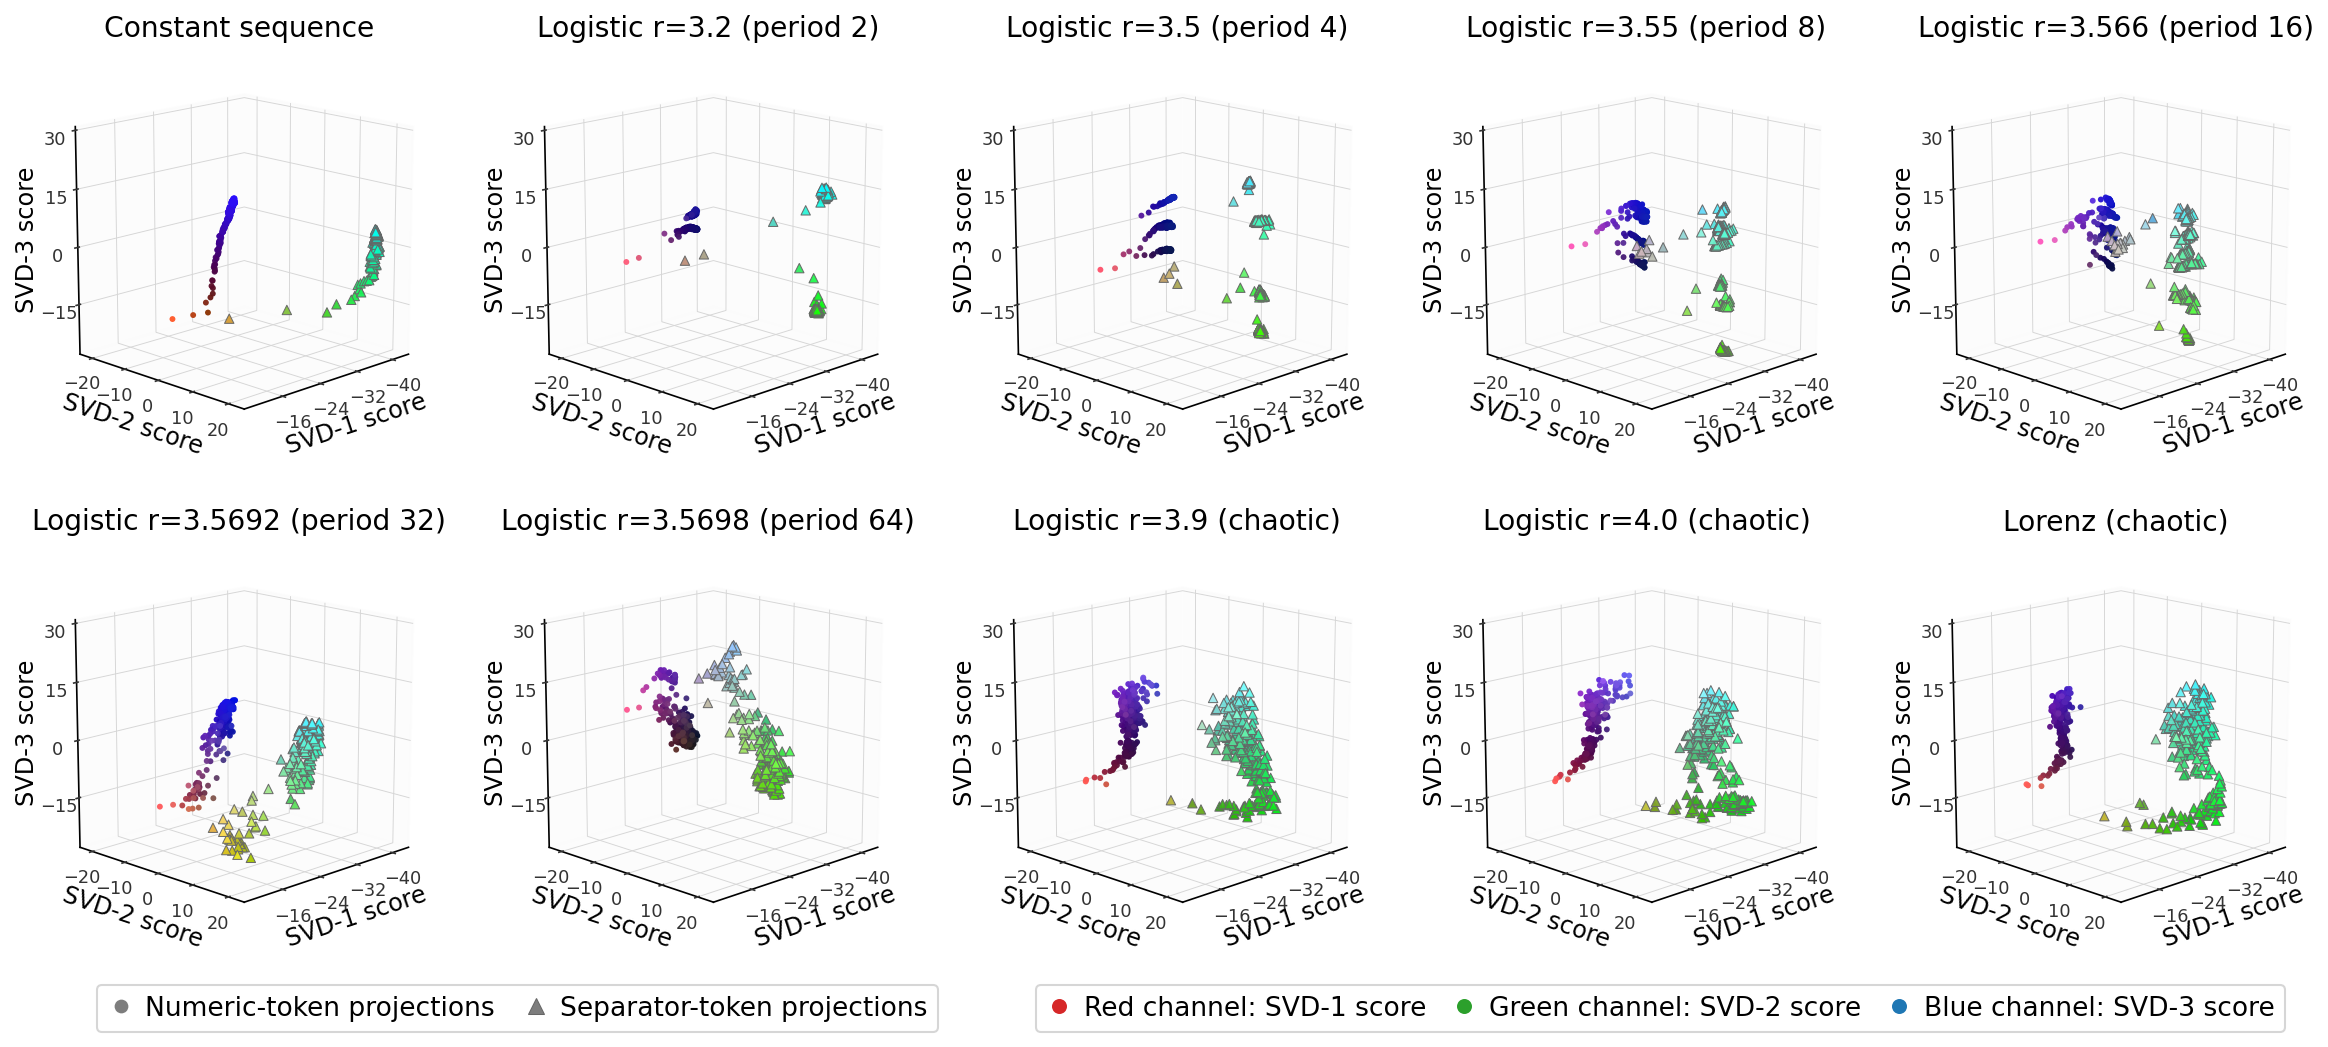

In [6]:
check_processed_svd_data(data_names=ALL_DATA_ORDER)
LAYER_INDEX = int(available_layer_indices(data_name=ALL_DATA_ORDER[0])[-1])

all_inputs_fig = plot_last_layer_svd_rgb_all_inputs(
    layer_index=LAYER_INDEX,
    svd_components=SVD_COMPONENTS,
    frac=CONTEXT_FRAC,
    save=True,
    save_filename='last_layer_signal_visualization_all_inputs.pdf',
    show=True,
)


Average cumulative SVD energy first across input families within each layer and then across layers; display and save the standalone PDF figure.


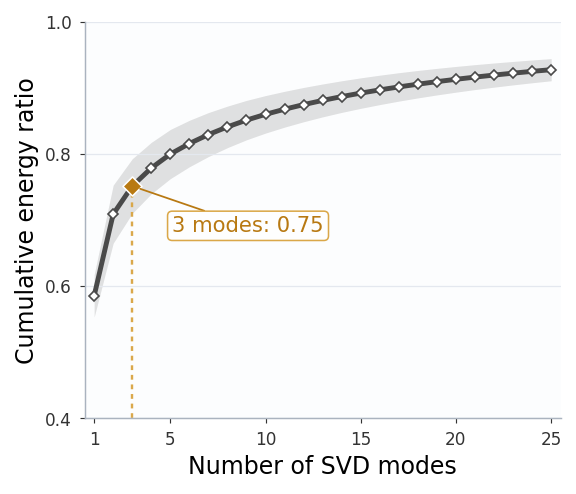

In [7]:
# Average cumulative SVD energy first across inputs within each layer, then across layers
cumulative_energy_only = collect_cumulative_energy_data(
    data_names=ENERGY_SUMMARY_DATA_ORDER,
    frac=CONTEXT_FRAC,
    data_dir=PROCESSED_DATA_DIR,
)

energy_only_fig, energy_only_ax = plt.subplots(
    figsize=ENERGY_FIGURE_SIZE,
    dpi=DISPLAY_DPI,
)
draw_cumulative_energy_panel(
    energy_only_ax,
    cumulative_energy_only,
    max_modes=ENERGY_PLOT_MAX_MODES,
)
energy_only_ax.set_box_aspect(ENERGY_PANEL_BOX_ASPECT / 1.2)
energy_only_fig.subplots_adjust(left=0.20, right=0.96, bottom=0.17, top=0.93)

FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
energy_only_fig.savefig(
    FIGURE_OUTPUT_DIR / 'cumulative_svd_energy.pdf',
    bbox_inches='tight',
    pad_inches=ENERGY_SAVEFIG_PAD_INCHES,
    dpi=PDF_DPI,
)
plt.show()
